In [1]:
%pip -q install imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.datasets import make_classification

In [2]:
# Dataset sintetis untuk simulasi
X, y = make_classification(
    n_samples=2000,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    weights=[0.95, 0.05],
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=[f"fitur_{i}" for i in range(8)]
)

df["target"] = y

# Simulasikan missing values
rng = np.random.default_rng(42)

mask = rng.random(df[[f"fitur_{i}" for i in range(8)]].shape) < 0.05

df_missing = df.copy()

df_missing.loc[:, [f"fitur_{i}" for i in range(8)]] = (
    df_missing[[f"fitur_{i}" for i in range(8)]].mask(mask)
)

print("Distribusi target:")
print(df["target"].value_counts().sort_index())

print("\nMissing values:")
print(df_missing.isnull().sum())

Distribusi target:
target
0    1896
1     104
Name: count, dtype: int64

Missing values:
fitur_0    101
fitur_1    107
fitur_2    112
fitur_3     88
fitur_4     89
fitur_5    100
fitur_6    101
fitur_7     90
target       0
dtype: int64


In [3]:
# Imputasi missing values dengan KNN Imputer
imputer = KNNImputer(n_neighbors=5)

fitur_cols = [
    c for c in df_missing.columns
    if c.startswith("fitur")
]

df_imputed = df_missing.copy()

df_imputed[fitur_cols] = imputer.fit_transform(
    df_missing[fitur_cols]
)

# Deteksi outlier dengan Isolation Forest
iso = IsolationForest(
    contamination=0.02,
    random_state=42
)

df_imputed["is_outlier"] = iso.fit_predict(
    df_imputed[fitur_cols]
)

print(
    "Jumlah outlier terdeteksi:",
    (df_imputed["is_outlier"] == -1).sum()
)

Jumlah outlier terdeteksi: 40


In [4]:
X = df_imputed[fitur_cols]
y = df_imputed["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Model tanpa SMOTE
model_base = LogisticRegression(max_iter=1000)
model_base.fit(X_train, y_train)

# SMOTE hanya diterapkan pada data training
smote = SMOTE(random_state=42)

X_train_sm, y_train_sm = smote.fit_resample(
    X_train, y_train
)

model_smote = LogisticRegression(max_iter=1000)

model_smote.fit(X_train_sm, y_train_sm)

print("Kelas train sebelum SMOTE:")
print(y_train.value_counts().sort_index())

print("\nKelas train setelah SMOTE:")
print(pd.Series(y_train_sm).value_counts().sort_index())

Kelas train sebelum SMOTE:
target
0    1517
1      83
Name: count, dtype: int64

Kelas train setelah SMOTE:
target
0    1517
1    1517
Name: count, dtype: int64


In [5]:
for nama, model in [
    ("Baseline tanpa SMOTE", model_base),
    ("Dengan SMOTE", model_smote)
]:
    y_pred = model.predict(X_test)

    print("\n", nama)
    print(
        "Akurasi:",
        round(accuracy_score(y_test, y_pred), 3)
    )
    print(
        "F1-Score:",
        round(f1_score(y_test, y_pred, zero_division=0), 3)
    )

    print(classification_report(
        y_test, y_pred, zero_division=0
    ))


 Baseline tanpa SMOTE
Akurasi: 0.948
F1-Score: 0.0
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       379
           1       0.00      0.00      0.00        21

    accuracy                           0.95       400
   macro avg       0.47      0.50      0.49       400
weighted avg       0.90      0.95      0.92       400


 Dengan SMOTE
Akurasi: 0.78
F1-Score: 0.267
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       379
           1       0.16      0.76      0.27        21

    accuracy                           0.78       400
   macro avg       0.57      0.77      0.57       400
weighted avg       0.94      0.78      0.84       400



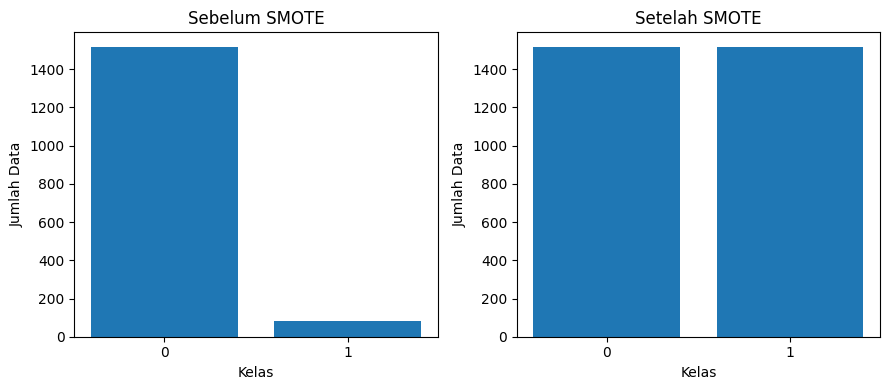

In [6]:
before = y_train.value_counts().sort_index()
after = pd.Series(y_train_sm).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].bar(before.index.astype(str), before.values)
axes[0].set_title("Sebelum SMOTE")
axes[0].set_xlabel("Kelas")
axes[0].set_ylabel("Jumlah Data")

axes[1].bar(after.index.astype(str), after.values)
axes[1].set_title("Setelah SMOTE")
axes[1].set_xlabel("Kelas")
axes[1].set_ylabel("Jumlah Data")

plt.tight_layout()
plt.show()

In [7]:
# 1. Baseline tanpa penanganan
model_base = LogisticRegression(max_iter=1000)
model_base.fit(X_train, y_train)

# 2. SMOTE
model_smote = LogisticRegression(max_iter=1000)
model_smote.fit(X_train_sm, y_train_sm)

# 3. Undersampling
rus = RandomUnderSampler(random_state=42)

X_train_rus, y_train_rus = rus.fit_resample(
    X_train, y_train
)

model_rus = LogisticRegression(max_iter=1000)
model_rus.fit(X_train_rus, y_train_rus)

# 4. Class weight
model_cw = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model_cw.fit(X_train, y_train)

# Membandingkan F1-Score
model_list = [
    ("Baseline", model_base),
    ("SMOTE", model_smote),
    ("Undersampling", model_rus),
    ("Class Weight", model_cw)
]

hasil = []

for nama, model in model_list:
    y_pred = model.predict(X_test)

    hasil.append({
        "Pendekatan": nama,
        "Akurasi": accuracy_score(y_test, y_pred),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

df_hasil = pd.DataFrame(hasil)

df_hasil = df_hasil.sort_values(
    by="F1-Score",
    ascending=False
)

display(df_hasil.round(3))

terbaik = df_hasil.iloc[0]

print(
    "\nPendekatan dengan F1-Score tertinggi:",
    terbaik["Pendekatan"]
)

print(
    "Nilai F1-Score:",
    round(terbaik["F1-Score"], 3)
)

,Pendekatan,Akurasi,F1-Score
1,SMOTE,0.780,0.267
3,Class Weight,0.768,0.256
2,Undersampling,0.738,0.234
0,Baseline,0.948,0.000



Pendekatan dengan F1-Score tertinggi: SMOTE
Nilai F1-Score: 0.267
